# Loanliness: models

Supervised models from the paper (Table III, Figures 1 and 3), trained on the splits written by `loan_pipeline.ipynb`. Run that notebook first; this one only reads `artifacts/` through `loan_utils.py` and does no preprocessing of its own.

Protocol, as in the paper and the authors' code: every model is trained on the down-sampled train set and scored on the balanced test set. Scores on the natural-ratio test are kept next to it for reference.

## 1. Load the splits

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve
from sklearn.model_selection import GridSearchCV
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier

from loan_utils import ARTIFACTS as OUT, SEED, load_split, metrics

X_train, y_train = load_split("train_balanced")
tests = {"balanced": load_split("test_balanced"), "natural": load_split("test")}
X_test, y_test = tests["balanced"]
print("train:", X_train.shape, y_train.mean(), "|", {k: (X.shape, round(y.mean(), 4)) for k, (X, y) in tests.items()})

train: (39720, 700) 0.5 | {'balanced': ((9930, 700), np.float64(0.5)), 'natural': ((61503, 700), np.float64(0.0807))}


## 2. The five classifiers (Table III)

All five get the same balanced train rows, so no class weights are needed. Features are already min-max scaled to [0, 1] by the pipeline.

In [2]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=15, random_state=SEED, n_jobs=-1),
    "Naive Bayes": GaussianNB(),
    "Multi-layer Perceptron": MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=50, early_stopping=True, random_state=SEED),
    "LightGBM": LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, random_state=SEED, n_jobs=-1, verbosity=-1),
}

def score(m):
    # metrics on both test sets, plus the balanced-test probabilities for the ROC plot
    return {t: metrics(y, m.predict(X), m.predict_proba(X)[:, 1]) for t, (X, y) in tests.items()}

scores = {name: score(m.fit(X_train, y_train)) for name, m in models.items()}
probs = {name: m.predict_proba(X_test)[:, 1] for name, m in models.items()}

In [3]:
# paper Table III: accuracy, precision / recall / F1 as class 0 / class 1
paper = pd.DataFrame({
    "Logistic Regression": [0.6934, "0.66/0.75", "0.81/0.58", "0.72/0.65"],
    "Random Forest": [0.6351, "0.58/1.00", "1.00/0.27", "0.73/0.43"],
    "Naive Bayes": [0.5211, "0.51/0.71", "0.97/0.07", "0.67/0.13"],
    "Multi-layer Perceptron": [0.6915, "0.67/0.71", "0.73/0.65", "0.70/0.68"],
    "LightGBM": [0.5747, "0.54/1.00", "1.00/0.15", "0.70/0.26"],
}, index=["Accuracy", "Precision (0/1)", "Recall (0/1)", "F1 (0/1)"]).T

def table_iii(scores, test):
    t = pd.DataFrame({name: s[test] for name, s in scores.items()}).T
    pair = lambda a: t[a + "_0"].map("{:.2f}".format) + "/" + t[a + "_1"].map("{:.2f}".format)
    return pd.DataFrame({"Accuracy": t["accuracy"].round(4), "Precision (0/1)": pair("prec"), "Recall (0/1)": pair("rec"),
                         "F1 (0/1)": pair("f1"), "AUC": t["auc"].round(3)})

res = table_iii(scores, "balanced")
res.to_csv(OUT / "table3.csv")
print("Table III, balanced test (paper protocol)"); display(res.join(paper, rsuffix=", paper"))
print("Table III, natural-ratio test"); display(table_iii(scores, "natural"))

Table III, balanced test (paper protocol)


,Accuracy,Precision (0/1),Recall (0/1),F1 (0/1),AUC,"Accuracy, paper","Precision (0/1), paper","Recall (0/1), paper","F1 (0/1), paper"
Logistic Regression,0.6744,0.68/0.67,0.67/0.68,0.67/0.68,0.735,0.6934,0.66/0.75,0.81/0.58,0.72/0.65
Random Forest,0.6688,0.67/0.67,0.68/0.66,0.67/0.67,0.726,0.6351,0.58/1.00,1.00/0.27,0.73/0.43
Naive Bayes,0.5907,0.57/0.63,0.75/0.44,0.65/0.52,0.630,0.5211,0.51/0.71,0.97/0.07,0.67/0.13
Multi-layer Perceptron,0.6695,0.70/0.65,0.59/0.74,0.64/0.69,0.727,0.6915,0.67/0.71,0.73/0.65,0.70/0.68
LightGBM,0.6877,0.69/0.69,0.68/0.69,0.69/0.69,0.753,0.5747,0.54/1.00,1.00/0.15,0.70/0.26


Table III, natural-ratio test


,Accuracy,Precision (0/1),Recall (0/1),F1 (0/1),AUC
Logistic Regression,0.6758,0.96/0.16,0.68/0.68,0.79/0.25,0.738
Random Forest,0.6770,0.96/0.15,0.68/0.66,0.79/0.25,0.726
Naive Bayes,0.7252,0.94/0.13,0.75/0.44,0.83/0.20,0.636
Multi-layer Perceptron,0.6019,0.96/0.14,0.59/0.74,0.73/0.23,0.729
LightGBM,0.6888,0.96/0.16,0.69/0.69,0.80/0.26,0.756


**Findings.** On the balanced test LightGBM is best at 0.688 accuracy, then logistic regression (0.674), the MLP (0.670), random forest (0.669) and Naive Bayes (0.591). Logistic regression and the MLP land within about two points of the paper (69.3% and 69.2%), and Naive Bayes is the weakest model in both, though less extreme here (recall on defaults 0.44 against the paper's 0.07).

The paper's random forest and LightGBM rows are not reproduced. It reports positive-class precision 1.00 with recall 0.27 and 0.15, so both models come out below logistic regression. Trained on the down-sampled set, ours are balanced across the two classes (precision and recall 0.66 to 0.69) and LightGBM is the best model, not the second worst. Section 5 of `loan_pipeline.ipynb` shows that the paper's shape is what a LightGBM trained without balancing produces.

At the natural ratio each model keeps its recall and AUC, and precision on defaults falls to 0.13 to 0.16 because only 8% of the rows are defaults. Accuracy there is not a useful ranking: Naive Bayes has the highest accuracy (0.725) and the lowest AUC (0.636).

## 3. ROC curves (Figure 1)

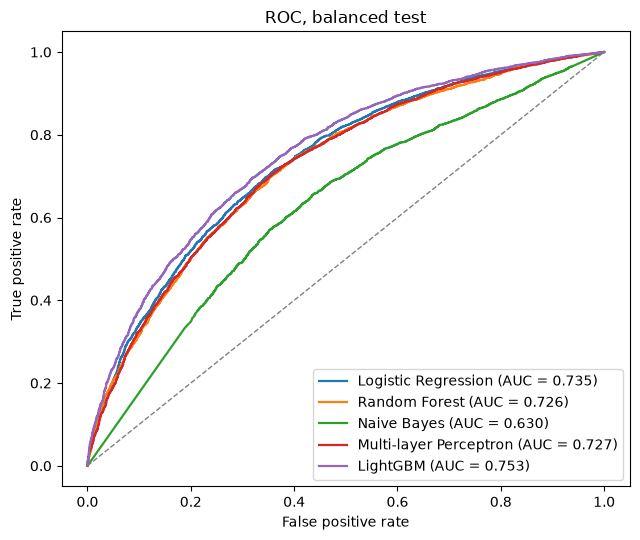

In [4]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    ax.plot(fpr, tpr, lw=1.6, label=f"{name} (AUC = {scores[name]['balanced']['auc']:.3f})")
ax.plot([0, 1], [0, 1], ls="--", c="grey", lw=1)
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate"); ax.set_title("ROC, balanced test")
ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(OUT / "figure1_roc.png", dpi=150); plt.show()

**Findings.** AUC orders the models as LightGBM (0.753), logistic regression (0.735), MLP (0.727), random forest (0.726), Naive Bayes (0.630). The paper has the MLP first, followed by random forest and logistic regression; here those three are within 0.01 of each other, so their order is not meaningful, and LightGBM is ahead of all of them.

## 4. Random forest tuning

3-fold grid search on the balanced train set, selected by ROC-AUC. The test set is not used for the selection.

In [5]:
grid = GridSearchCV(
    RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1),
    {"max_depth": [6, 10, 15, None], "min_samples_leaf": [1, 5, 20], "max_features": ["sqrt", 0.1]},
    scoring="roc_auc", cv=3, n_jobs=-1).fit(X_train, y_train)

cv = pd.DataFrame(grid.cv_results_)
print("best:", grid.best_params_, "| CV AUC:", round(grid.best_score_, 4))
cv = cv.assign(max_depth=cv["param_max_depth"].astype(object).fillna("None").astype(str), max_features=cv["param_max_features"].astype(str), min_samples_leaf=cv["param_min_samples_leaf"].astype(int))
cv.pivot_table(index=["max_features", "min_samples_leaf"], columns="max_depth", values="mean_test_score").round(4)

best: {'max_depth': None, 'max_features': 0.1, 'min_samples_leaf': 5} | CV AUC: 0.7227


max_depth                          10      15       6    None
max_features min_samples_leaf                                
0.1          1                 0.7170  0.7200  0.6992  0.7181
             5                 0.7166  0.7207  0.6992  0.7227
             20                0.7161  0.7202  0.6996  0.7217
sqrt         1                 0.7123  0.7162  0.6964  0.7162
             5                 0.7127  0.7176  0.6972  0.7189
             20                0.7122  0.7166  0.6970  0.7167

In [6]:
rf_tuned = grid.best_estimator_
tuned = {"Random Forest": scores["Random Forest"], "Random Forest, tuned": score(rf_tuned)}
json.dump(grid.best_params_, open(OUT / "rf_best_params.json", "w"))
print("balanced test"); display(table_iii(tuned, "balanced"))
print("natural-ratio test"); display(table_iii(tuned, "natural"))

balanced test


,Accuracy,Precision (0/1),Recall (0/1),F1 (0/1),AUC
Random Forest,0.6688,0.67/0.67,0.68/0.66,0.67/0.67,0.726
"Random Forest, tuned",0.6717,0.67/0.67,0.68/0.66,0.67/0.67,0.732


natural-ratio test


,Accuracy,Precision (0/1),Recall (0/1),F1 (0/1),AUC
Random Forest,0.677,0.96/0.15,0.68/0.66,0.79/0.25,0.726
"Random Forest, tuned",0.676,0.96/0.15,0.68/0.66,0.79/0.25,0.731


**Findings.** The search picks unbounded depth, `max_features=0.1` and `min_samples_leaf=5` (CV AUC 0.7227). Depth matters most: depth 6 gives about 0.70 and depth 15 about 0.72, while `min_samples_leaf` changes the third decimal. On the balanced test the tuned forest moves from 0.669 to 0.672 accuracy and from 0.726 to 0.732 AUC, still below logistic regression and LightGBM. The best setting sits on the edge of the grid for depth and `max_features`, so a little more may be available, but the gain so far is small.

## 5. Feature importance (Figure 3)

Impurity importance from the tuned random forest, top 20.

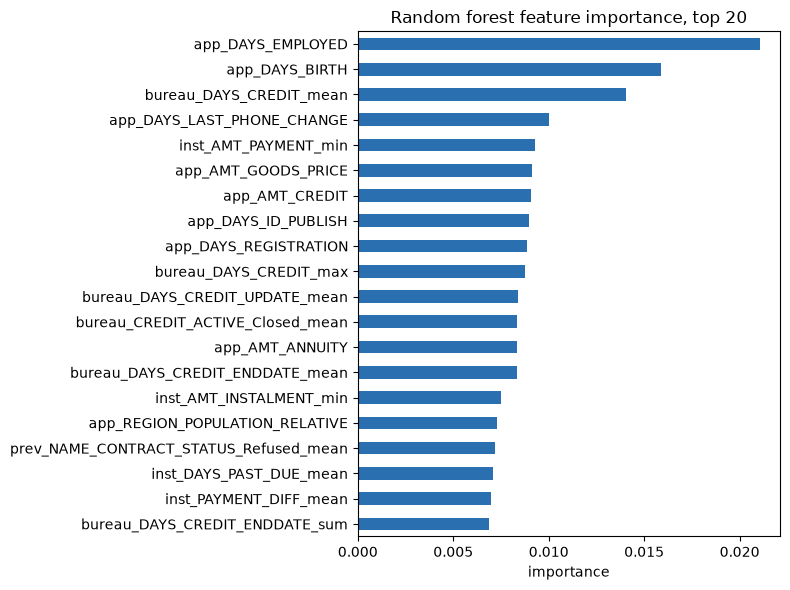

app_DAYS_EMPLOYED                         0.0211
app_DAYS_BIRTH                            0.0159
bureau_DAYS_CREDIT_mean                   0.0141
app_DAYS_LAST_PHONE_CHANGE                0.0100
inst_AMT_PAYMENT_min                      0.0093
app_AMT_GOODS_PRICE                       0.0091
app_AMT_CREDIT                            0.0091
app_DAYS_ID_PUBLISH                       0.0089
app_DAYS_REGISTRATION                     0.0089
bureau_DAYS_CREDIT_max                    0.0087
bureau_DAYS_CREDIT_UPDATE_mean            0.0084
bureau_CREDIT_ACTIVE_Closed_mean          0.0083
app_AMT_ANNUITY                           0.0083
bureau_DAYS_CREDIT_ENDDATE_mean           0.0083
inst_AMT_INSTALMENT_min                   0.0075
app_REGION_POPULATION_RELATIVE            0.0073
prev_NAME_CONTRACT_STATUS_Refused_mean    0.0072
inst_DAYS_PAST_DUE_mean                   0.0071
inst_PAYMENT_DIFF_mean                    0.0070
bureau_DAYS_CREDIT_ENDDATE_sum            0.0069
dtype: float64

In [7]:
imp = pd.Series(rf_tuned.feature_importances_, index=X_train.columns).nlargest(20)
ax = imp[::-1].plot.barh(figsize=(8, 6), color="#2a6fb0", title="Random forest feature importance, top 20")
ax.set_xlabel("importance"); ax.xaxis.set_major_locator(plt.MaxNLocator(5))
plt.tight_layout(); plt.savefig(OUT / "figure3_importance.png", dpi=150); plt.show()
imp.round(4)

**Findings.** The two most important features are `DAYS_EMPLOYED` and `DAYS_BIRTH`, the same two the paper names for its Figure 3. Most of the rest are also timing features (`DAYS_*`) from the application and the bureau records, followed by loan amounts and installment payment aggregates. Importance is spread thinly: the top feature has 0.021 of the total over 700 features. Impurity importance favours continuous columns over the one-hot ones, so the ranking of the binary features is understated.

## Notes on differences from the paper

- **Protocol:** all five models use the same down-sampled train set and balanced test set from `loan_pipeline.ipynb`; the feature differences listed there (no `EXT_SOURCE`, `previous_application` included, mean imputation) apply here too.
- **Hyperparameters:** the paper does not list them, so they are ours: logistic regression with default L2, random forest with 200 trees, a (128, 64) MLP with early stopping, LightGBM with 300 trees at learning rate 0.05. All predictions use a 0.5 threshold.
- **Table III:** logistic regression and MLP are reproduced to within about two points; the random forest and LightGBM rows are not, and LightGBM is our best model.
- **Figure 1:** LightGBM has the best AUC here, not the MLP.
- **Figure 3:** the top two features match.